In [17]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import time
import os
import numpy as np

# Use CUDA when available, otherwise CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
from linear_transformer import (
    Transformer_F,
    Transformer_F_Looped,
    attention,
    generate_data,
    in_context_loss,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

print(f'Running on device: {device}.')

Running on device: cuda.


In [18]:
# Set up problem parameters

lr = 0.001
clip_r = 1000
alg = 'adam'
mode = 'normal'

N = 10     # context length (no assumption given in paper)
d = 5        # dimension

n_head = 1  # 1-headed attention
B = 4000  # 4000 minibatch size
var = 0.05  # initializations scale of transformer parameter
shape_k = 0.1  # shape_k: parameter for Gamma distributed covariates
max_iters = 10000  # Number of Iterations to run
hist_stride = 1  # stride for saved model paramters in `train.ipynb'
stride = 100

# a convenience function for taking a step and clipping
def clip_and_step(allparam, optimizer, clip_r = None):
    grad_all = allparam.grad
    norm_p = grad_all.norm().item()
    
    if clip_r is not None:
        if norm_p > clip_r:
            grad_all.mul_(clip_r / norm_p)

    if np.isfinite(norm_p):
        optimizer.step()

    return norm_p

In [19]:
####################################
# train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)


def run_experiment_suite(seeds, n_layers_loops, model_types, filename, context_lengths=None):
    """Train every (seed, count, model_type, context_length) combination and save all histories to `filename`.

    `context_lengths` is a list of context lengths; it defaults to [N].
    """
    if context_lengths is None:
        context_lengths = [N]
    else:
        context_lengths = list(context_lengths)

    keys = [(seed, count, model_type, context_length)
            for seed in seeds
            for count in n_layers_loops
            for model_type in model_types
            for context_length in context_lengths]

    hist_dict = {}
    for run_index, key in enumerate(keys, start=1):
        seed, count, model_type, context_length = key
        print(f'Run {run_index}/{len(keys)}: seed={seed}, count={count}, type={model_type}, N={context_length}')
        hist_dict[key] = []

        torch.manual_seed(seed)
        if model_type == 'layered':
            model = Transformer_F(count, n_head, d, var)
        elif model_type == 'looped':
            model = Transformer_F_Looped(count, n_head, d, var)
        else:
            raise ValueError(f'Unsupported model type: {model_type}')
        model = model.to(device)

        if alg == 'sgd':
            optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
        elif alg == 'adam':
            optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.9), weight_decay=0)
        else:
            raise ValueError(f'Unsupported optimizer: {alg}')

        np.random.seed(seed)
        torch.manual_seed(seed)
        for t in range(max_iters):
            start = time.time()
            if t % hist_stride == 0:
                hist_dict[key].append(model.allparam.detach().clone())

            Z, y = generate_data(mode, context_length, d, B, shape_k)
            Z = Z.to(device)
            y = y.to(device)
            loss = in_context_loss(model, Z, y)

            loss.backward()

            grad_norm = clip_and_step(model.allparam, optimizer, clip_r=clip_r)

            if not np.isfinite(grad_norm):
                print(f'[DEBUG] [Norm]: infinite gradient norm at iteration {t}.')

            optimizer.zero_grad()
            end = time.time()

            # Only prints for the first 5 iterations, and then every 100 iterations
            if t % 100 == 0 or t < 5:
                print(f'iter {t} | Loss: {loss.item()} | time: {end-start} | gradnorm: {grad_norm}')

        print(f'Finished seed={seed}, count={count}, type={model_type}, N={context_length}.')

    torch.save({'hist_dict': hist_dict}, filename)
    print(f'Saved histories to {filename}')
    return hist_dict


In [9]:
seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['layered', 'looped']

hist_dict = run_experiment_suite(seeds, n_layers_loops, model_types, filename)

Run 1/24: seed=0, count=1, type=layered
iter 0 | Loss: 4.782515525817871 | time: 0.29356908798217773 | gradnorm: 3.1331946849823
iter 1 | Loss: 4.460882663726807 | time: 0.004599809646606445 | gradnorm: 3.160719156265259
iter 2 | Loss: 4.659054756164551 | time: 0.0033473968505859375 | gradnorm: 3.2489049434661865
iter 3 | Loss: 4.460082054138184 | time: 0.003236532211303711 | gradnorm: 3.143481969833374
iter 4 | Loss: 4.543564319610596 | time: 0.0029489994049072266 | gradnorm: 3.2081918716430664
iter 100 | Loss: 3.836466073989868 | time: 0.003622770309448242 | gradnorm: 3.024074077606201
iter 200 | Loss: 3.3473775386810303 | time: 0.0037698745727539062 | gradnorm: 2.7464020252227783
iter 300 | Loss: 2.8352458477020264 | time: 0.0036592483520507812 | gradnorm: 2.3970413208007812
iter 400 | Loss: 2.3862922191619873 | time: 0.0033435821533203125 | gradnorm: 1.8073077201843262
iter 500 | Loss: 2.0302138328552246 | time: 0.002863168716430664 | gradnorm: 1.1721309423446655
iter 600 | Loss: 1

KeyboardInterrupt: 

In [20]:
####################################
# compute test loss for available layered and looped checkpoints
####################################

TEST_SEED = 99


def compute_loss_dict(hist_dict):
    """Evaluate every checkpoint (every `stride` iterations) of each run on a fixed test batch."""
    loss_dict = {}

    for key, history in hist_dict.items():
        seed, count, model_type, context_length = key
        test_losses = torch.full((len(range(0, max_iters, stride)),), float('nan'))

        np.random.seed(TEST_SEED)
        torch.manual_seed(TEST_SEED)
        Z, y = generate_data(mode, context_length, d, B, shape_k)
        Z = Z.to(device)
        y = y.to(device)
        if model_type == 'layered':
            model = Transformer_F(count, n_head, d, var).to(device)
        else:
            model = Transformer_F_Looped(count, n_head, d, var).to(device)

        for iteration in range(0, max_iters, stride):
            if iteration % hist_stride != 0:
                continue
            history_index = iteration // hist_stride
            if history_index >= len(history):
                break
            snapshot = history[history_index]
            if not torch.isfinite(snapshot).all():
                continue

            with torch.no_grad():
                model.allparam.copy_(snapshot.to(device))
                test_losses[iteration // stride] = in_context_loss(model, Z, y).item()

        loss_dict[key] = test_losses

    return loss_dict


In [ ]:
hist_dict = torch.load(filename, map_location='cpu')['hist_dict']
loss_dict = compute_loss_dict(hist_dict)

In [21]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
iterations = np.arange(0, max_iters, stride)

MODEL_STYLES = {
    'layered': ('-', lambda count: f'{count}-layer transformer'),
    'looped': ('--', lambda count: f'{count}-loop shared-weight transformer'),
}


def plot_loss_curves(loss_dict, n_layers_loops, model_types, iterations,
                     fig_dir='figures', filename='figure_two_test_loss_layered_vs_looped.pdf',
                     seeds=None, log_scale=True, figsize=(9, 6)):
    """Plot mean +/- std test loss over seeds for each (count, model_type), one figure per context length.

    `seeds=None` uses all seeds; each figure is saved as `filename` with `_N{context_length}` appended to the stem.
    """
    stem, ext = os.path.splitext(filename)
    colors = dict(zip(n_layers_loops, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))

    for context_length in sorted({key[3] for key in loss_dict}):
        fig, ax = plt.subplots(1, 1, figsize=figsize)

        for count in n_layers_loops:
            for model_type in model_types:
                line_style, make_label = MODEL_STYLES[model_type]
                run_keys = [
                    key for key in loss_dict
                    if key[1] == count and key[2] == model_type and key[3] == context_length
                    and (seeds is None or key[0] in seeds)
                ]
                if not run_keys:
                    continue
                run_losses = torch.stack([loss_dict[key] for key in run_keys])
                valid = torch.isfinite(run_losses)
                n_valid = valid.sum(dim=0)
                safe_losses = torch.where(valid, run_losses, torch.zeros_like(run_losses))
                mean_loss = safe_losses.sum(dim=0) / n_valid.clamp_min(1)
                mean_loss[n_valid == 0] = float('nan')

                variance = torch.where(
                    valid,
                    (run_losses - mean_loss.unsqueeze(0)) ** 2,
                    torch.zeros_like(run_losses),
                ).sum(dim=0) / n_valid.clamp_min(1)
                std_loss = variance.sqrt()
                ax.plot(
                    iterations, mean_loss.numpy(), color=colors[count], linestyle=line_style,
                    lw=2.2, label=make_label(count),
                )
                multiple = n_valid > 1
                lower = torch.where(multiple, mean_loss - std_loss, torch.nan)
                upper = torch.where(multiple, mean_loss + std_loss, torch.nan)
                ax.fill_between(
                    iterations, lower.numpy(), upper.numpy(),
                    color=colors[count], alpha=0.10,
                )

        ax.set_title(f'N={context_length}')
        ax.set_xlabel('Iteration', fontsize=14)
        ax.set_ylabel('ICL Test Loss', fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=11)
        if log_scale:
            ax.set_yscale('log')
        ax.legend(fontsize=9, ncol=2)
        ax.grid(True, which='both', alpha=0.2)
        fig.tight_layout()
        fig.savefig(os.path.join(fig_dir, f'{stem}_N{context_length}{ext}'), dpi=600)
        plt.show()


In [ ]:
plot_loss_curves(loss_dict, n_layers_loops, ['layered', 'looped'], iterations, fig_dir=fig_dir)

In [22]:
####################################
# parameter matrices for both architectures
# layered models have a separate block per layer; looped models share one block
####################################

def plot_parameter_matrices(hist_dict, plot_seed, n_layers_loops, model_types, n_head,
                            hist_stride=1, fig_dir='figures'):
    """Plot the P/Q matrices of the last finite checkpoint for each (count, model_type, context_length) at `plot_seed`."""
    for context_length in sorted({key[3] for key in hist_dict}):
        for count in n_layers_loops:
            for model_type in model_types:
                key = (plot_seed, count, model_type, context_length)
                if key not in hist_dict:
                    print(f'No saved run found for {key}; skipping parameter plot.')
                    continue
                history = hist_dict[key]
                snapshot_index = next(
                    (idx for idx in range(len(history) - 1, -1, -1)
                     if torch.isfinite(history[idx]).all()),
                    None,
                )
                if snapshot_index is None:
                    print(f'No finite checkpoint found for {key}; skipping parameter plot.')
                    continue

                snapshot = history[snapshot_index].detach().cpu()
                block_count = snapshot.shape[0]
                fig, axs = plt.subplots(
                    2 * n_head, block_count,
                    figsize=(4 * block_count, 4 * 2 * n_head),
                    squeeze=False,
                )

                for head in range(n_head):
                    for block in range(block_count):
                        for matrix_type, matrix_name in enumerate(('P', 'Q')):
                            ax = axs[matrix_type * n_head + head, block]
                            matrix = snapshot[block, head, matrix_type]
                            im = ax.imshow(matrix, cmap='gray_r')
                            for row in range(matrix.shape[0]):
                                for col in range(matrix.shape[1]):
                                    ax.text(col, row, f'{matrix[row, col].item():.2f}',
                                            ha='center', va='center', color='r')
                            if model_type == 'looped':
                                title = f'shared {matrix_name}, head {head}'
                            else:
                                title = f'{matrix_name}, layer {block}, head {head}'
                            ax.set_title(title)
                            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

                fig.suptitle(
                    f'{model_type}: count={count}, N={context_length}, seed={plot_seed}, '
                    f'checkpoint={snapshot_index * hist_stride}',
                    fontsize=14,
                )
                fig.tight_layout()
                fig.savefig(
                    os.path.join(
                        fig_dir,
                        f'figure_two_parameters_{model_type}_count{count}_N{context_length}_seed{plot_seed}.pdf'),
                    dpi=600,
                    bbox_inches='tight',
                )
                plt.show()


In [ ]:
plot_parameter_matrices(hist_dict, seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)

In [23]:
########################################################
# compute distance-to-identity for both architectures
########################################################

def compute_dist_identity(M):
    scale = torch.diagonal(M).sum() / M.shape[0]
    ideal_identity = scale * torch.eye(M.shape[0], device=M.device, dtype=M.dtype)
    denominator = torch.linalg.norm(M, ord='fro')
    if not torch.isfinite(denominator) or denominator == 0:
        return float('nan')
    return (torch.linalg.norm(M - ideal_identity, ord='fro') / denominator).item()


def compute_dist_dict(hist_dict, iterations, n_head, hist_stride=1):
    """Return {key: tensor (count, P/Q, checkpoints)} of distance-to-identity.

    For looped models, the shared block is repeated across loop positions for a direct comparison.
    """
    dist_dict = {}

    for key, history in hist_dict.items():
        seed, count, model_type, context_length = key
        distances = torch.full((count, 2, len(iterations)), float('nan'))

        for point_index, iteration in enumerate(iterations):
            if iteration % hist_stride != 0:
                continue
            history_index = iteration // hist_stride
            if history_index >= len(history):
                break
            snapshot = history[history_index]
            if not torch.isfinite(snapshot).all():
                continue

            for block in range(count):
                source_block = block if model_type == 'layered' else 0
                for matrix_type in range(2):
                    head_distances = [
                        compute_dist_identity(snapshot[source_block, head, matrix_type])
                        for head in range(n_head)
                    ]
                    finite_distances = [value for value in head_distances if np.isfinite(value)]
                    if finite_distances:
                        distances[block, matrix_type, point_index] = float(np.mean(finite_distances))

        dist_dict[key] = distances

    return dist_dict


In [ ]:
iterations = np.arange(0, max_iters, stride)
dist_dict = compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)

In [24]:
########################################################
# integrated distance-to-identity comparison by depth/loop count
########################################################

def plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir='figures'):
    """Plot mean +/- std distance-to-identity over seeds, one figure per (layer/loop count, context length)."""
    for context_length in sorted({key[3] for key in dist_dict}):
        for count in n_layers_loops:
            fig, axs = plt.subplots(
                2, count,
                figsize=(4 * count, 8),
                squeeze=False,
                sharex=True,
            )

            for matrix_type, matrix_name in enumerate(('P', 'Q')):
                for block in range(count):
                    ax = axs[matrix_type, block]
                    for model_type, line_style, label in (
                        ('layered', '-', 'layered'),
                        ('looped', '--', 'looped (shared weights)'),
                    ):
                        run_keys = [
                            key for key in dist_dict
                            if key[1] == count and key[2] == model_type and key[3] == context_length
                        ]
                        if not run_keys:
                            continue

                        seed_curves = torch.stack([
                            dist_dict[key][block, matrix_type] for key in run_keys
                        ])
                        valid = torch.isfinite(seed_curves)
                        n_valid = valid.sum(dim=0)
                        values = torch.where(valid, seed_curves, torch.zeros_like(seed_curves))
                        mean = values.sum(dim=0) / n_valid.clamp_min(1)
                        mean[n_valid == 0] = float('nan')
                        variance = torch.where(
                            valid,
                            (seed_curves - mean.unsqueeze(0)) ** 2,
                            torch.zeros_like(seed_curves),
                        ).sum(dim=0) / n_valid.clamp_min(1)
                        std = variance.sqrt()

                        color = 'tab:blue' if matrix_type == 0 else 'tab:orange'
                        ax.plot(
                            iterations, mean.numpy(), color=color, linestyle=line_style,
                            lw=2, label=f'{label} {matrix_name}',
                        )
                        multiple = n_valid > 1
                        lower = torch.where(multiple, mean - std, torch.nan)
                        upper = torch.where(multiple, mean + std, torch.nan)
                        ax.fill_between(
                            iterations, lower.numpy(), upper.numpy(),
                            color=color, alpha=0.10,
                        )

                    ax.set_title(f'{matrix_name}, layer/loop {block}')
                    ax.set_ylim(bottom=0)
                    ax.grid(True, alpha=0.25)
                    if matrix_type == 0 and block == 0:
                        ax.legend(fontsize=8)

            for ax in axs[-1, :]:
                ax.set_xlabel('Iteration')
            axs[0, 0].set_ylabel('Distance to identity')
            axs[1, 0].set_ylabel('Distance to identity')
            fig.suptitle(
                f'Distance to identity: layered vs looped, count={count}, N={context_length}', fontsize=15)
            fig.tight_layout()
            fig.savefig(
                os.path.join(fig_dir, f'figure_two_dist_to_identity_count{count}_N{context_length}.pdf'),
                dpi=600,
                bbox_inches='tight',
            )
            plt.show()


In [ ]:
plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir=fig_dir)

Run 1/15: seed=0, count=5, type=looped, N=2
iter 0 | Loss: 8.224090576171875 | time: 0.01871800422668457 | gradnorm: 23.256296157836914
iter 1 | Loss: 8.118857383728027 | time: 0.014403581619262695 | gradnorm: 24.073047637939453
iter 2 | Loss: 7.912059783935547 | time: 0.015526533126831055 | gradnorm: 22.307273864746094
iter 3 | Loss: 7.685257911682129 | time: 0.015527725219726562 | gradnorm: 22.58423614501953
iter 4 | Loss: 7.724087715148926 | time: 0.015107393264770508 | gradnorm: 20.857467651367188
iter 100 | Loss: 4.103839874267578 | time: 0.01510763168334961 | gradnorm: 13.311128616333008
iter 200 | Loss: 3.285475254058838 | time: 0.014558792114257812 | gradnorm: 4.286308288574219
iter 300 | Loss: 3.0148446559906006 | time: 0.012174367904663086 | gradnorm: 1.0014686584472656
iter 400 | Loss: 2.988403558731079 | time: 0.013481855392456055 | gradnorm: 0.7710242867469788
iter 500 | Loss: 2.9737586975097656 | time: 0.015573740005493164 | gradnorm: 0.573298990726471
iter 600 | Loss: 2.

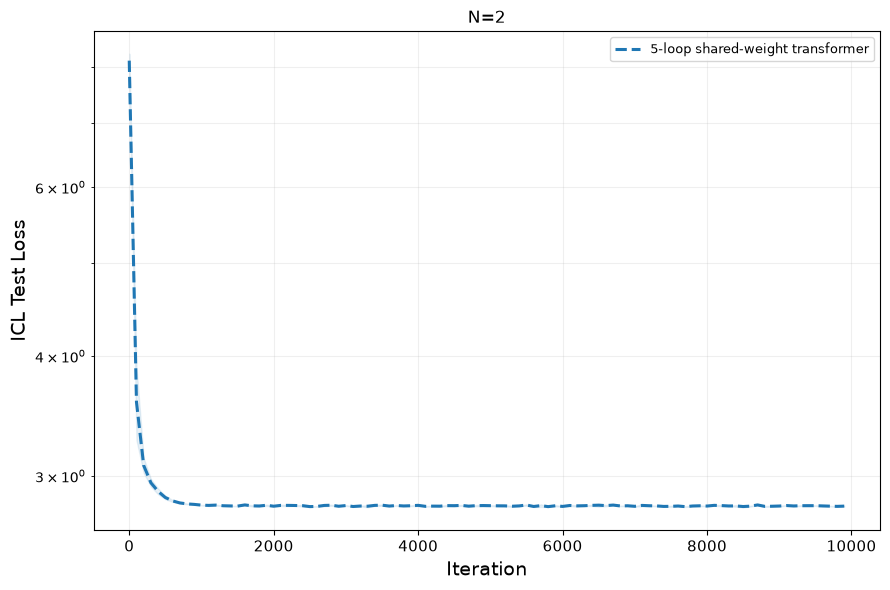

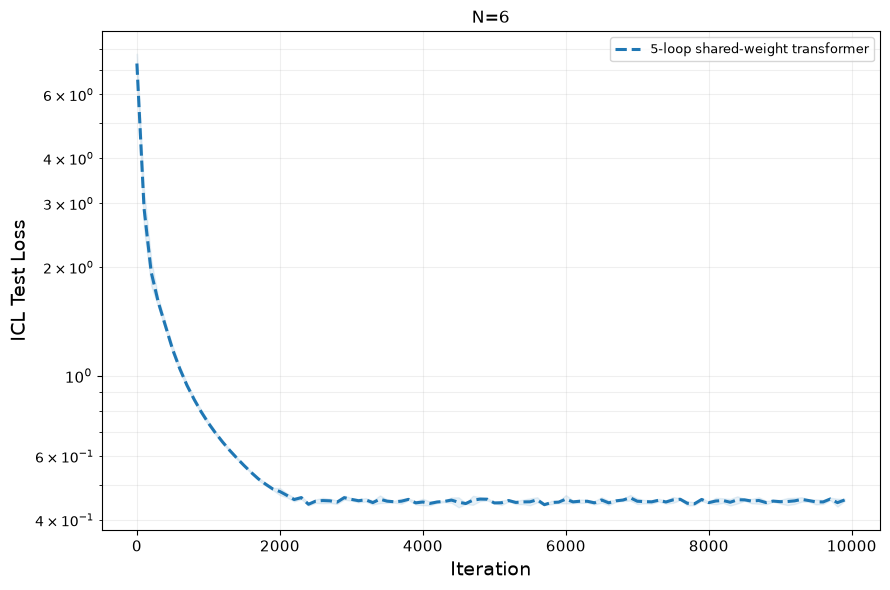

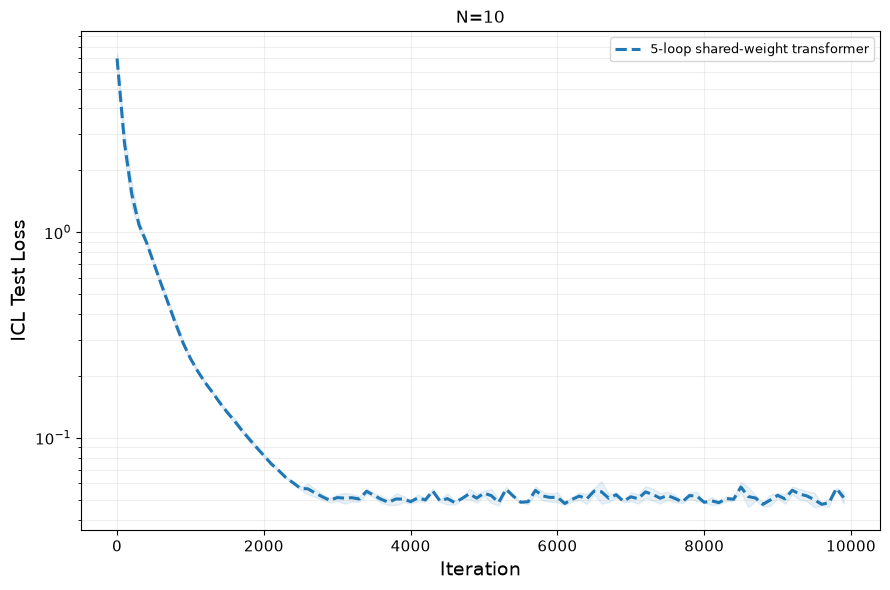

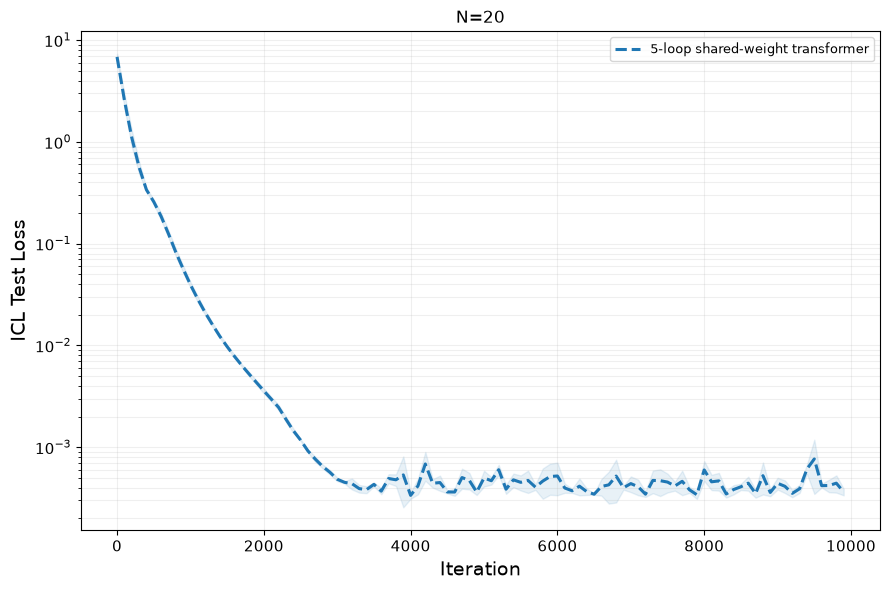

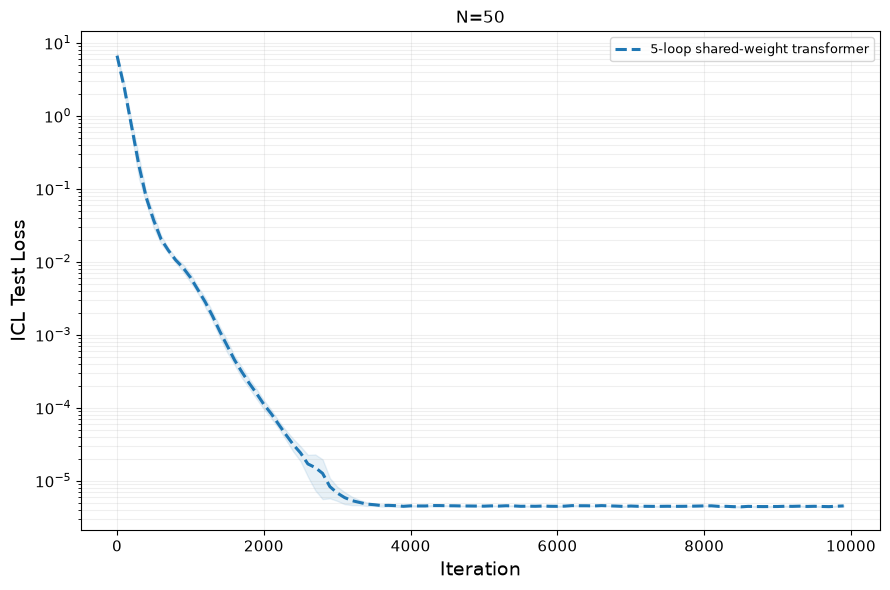

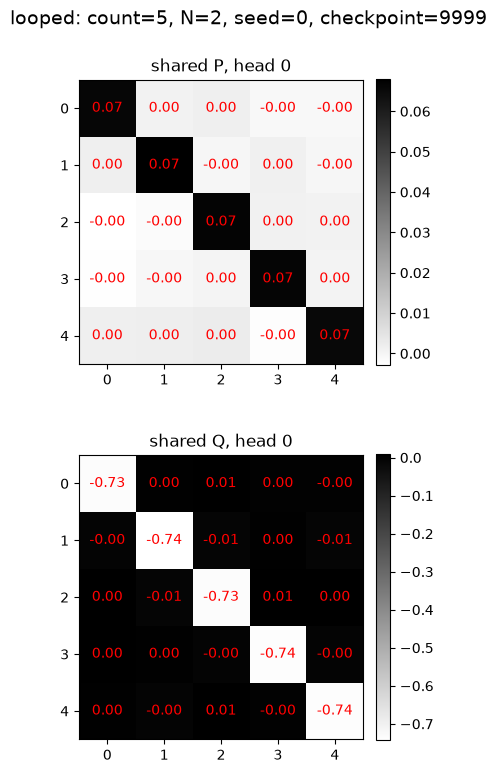

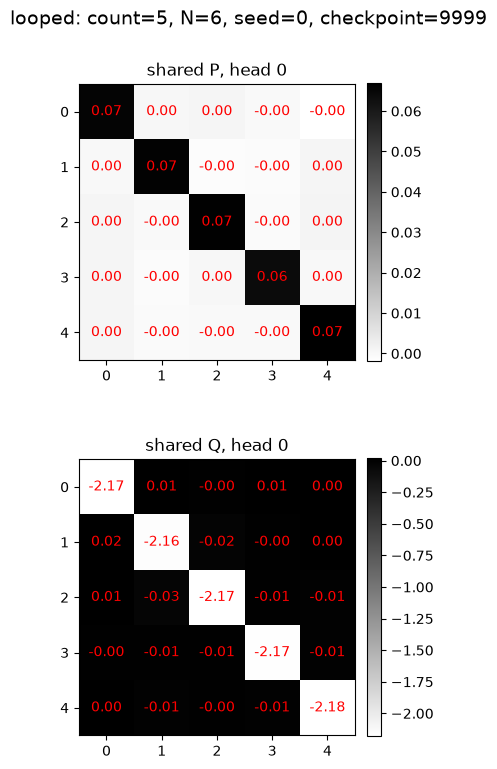

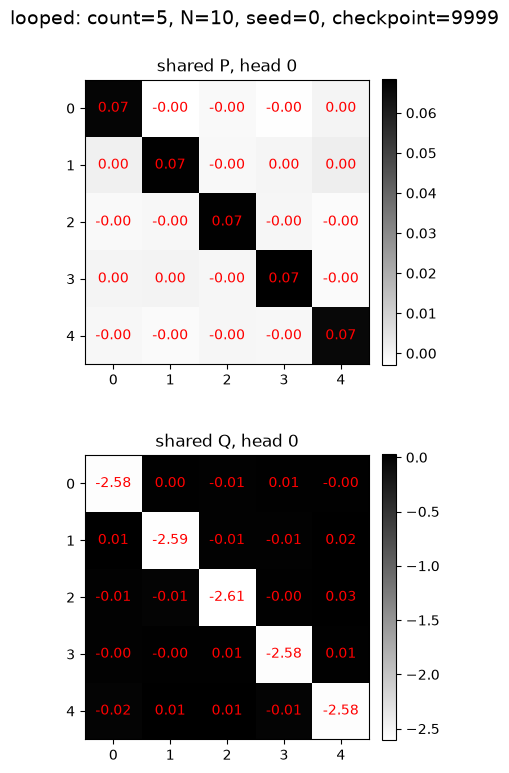

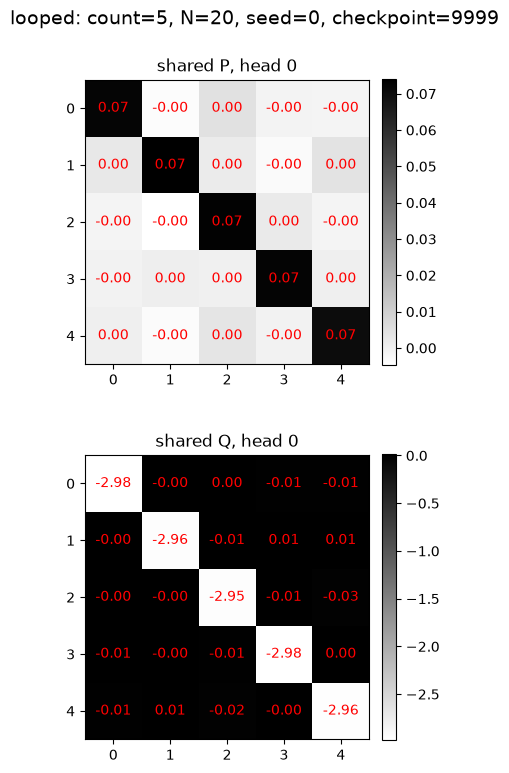

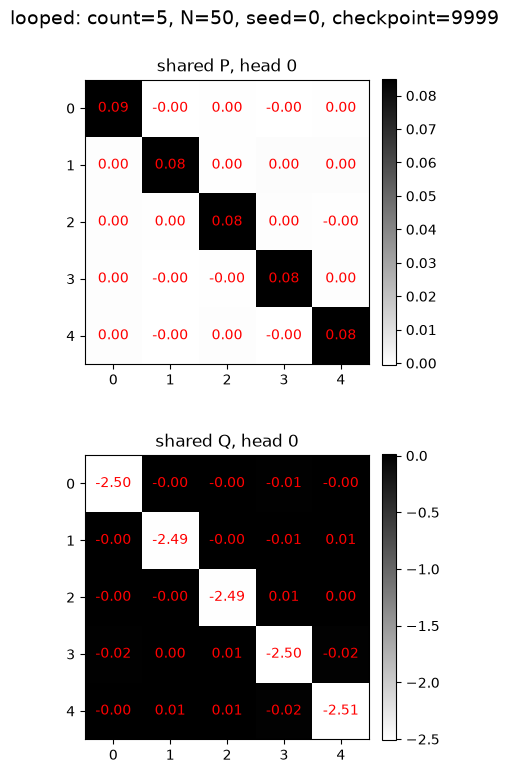

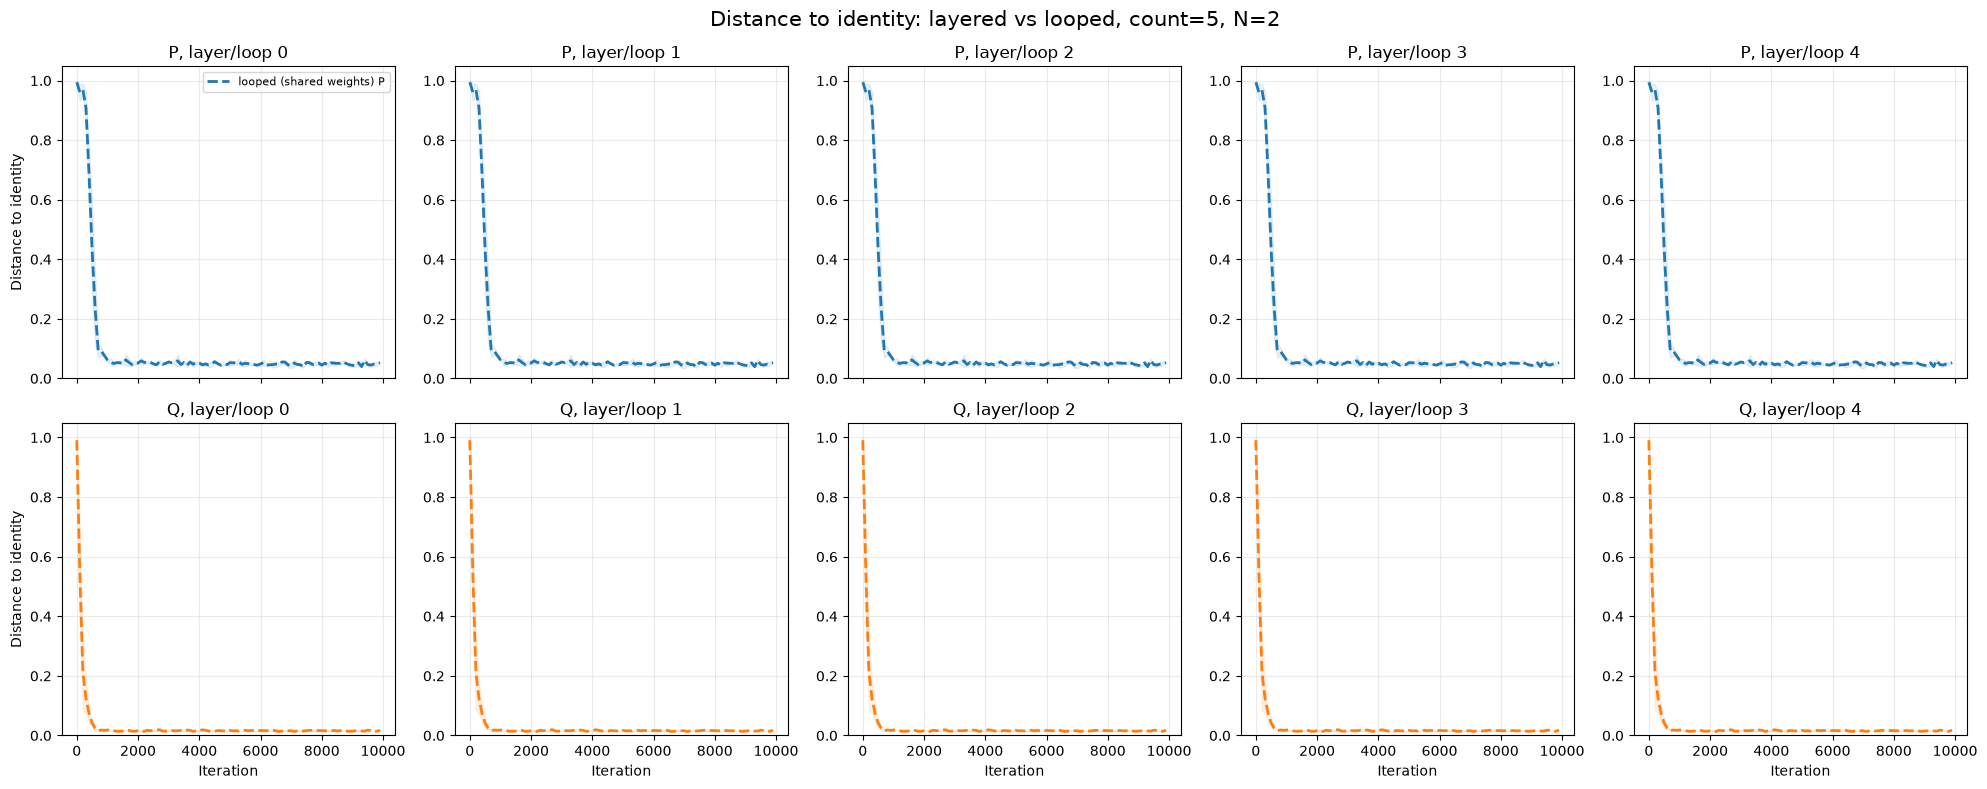

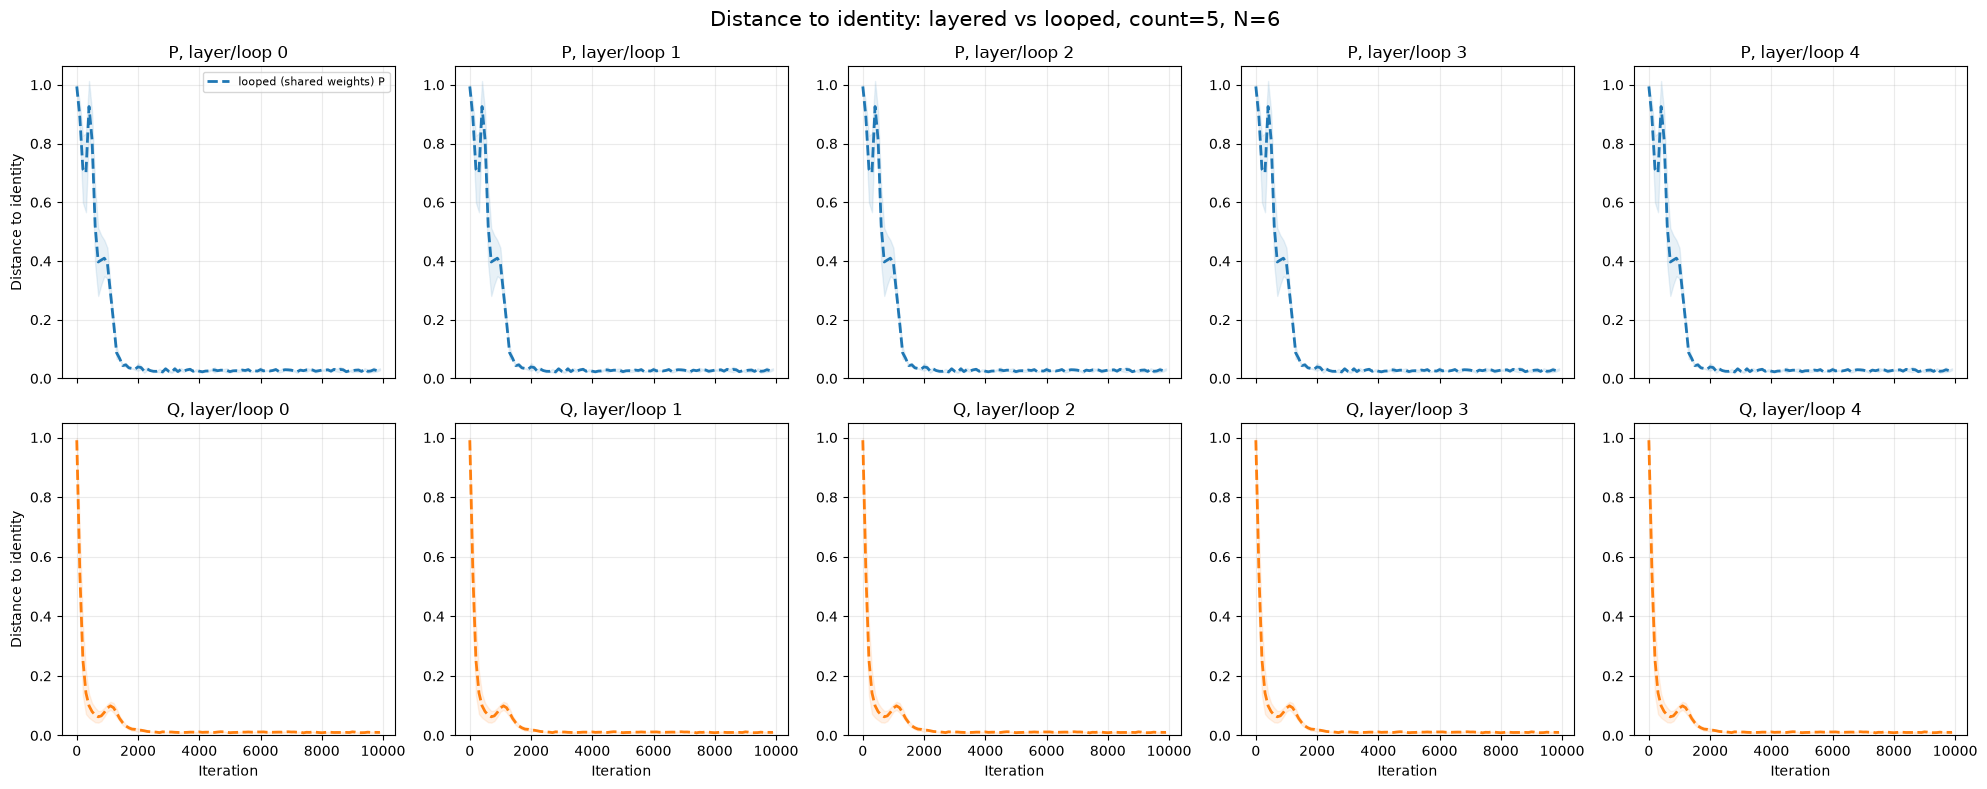

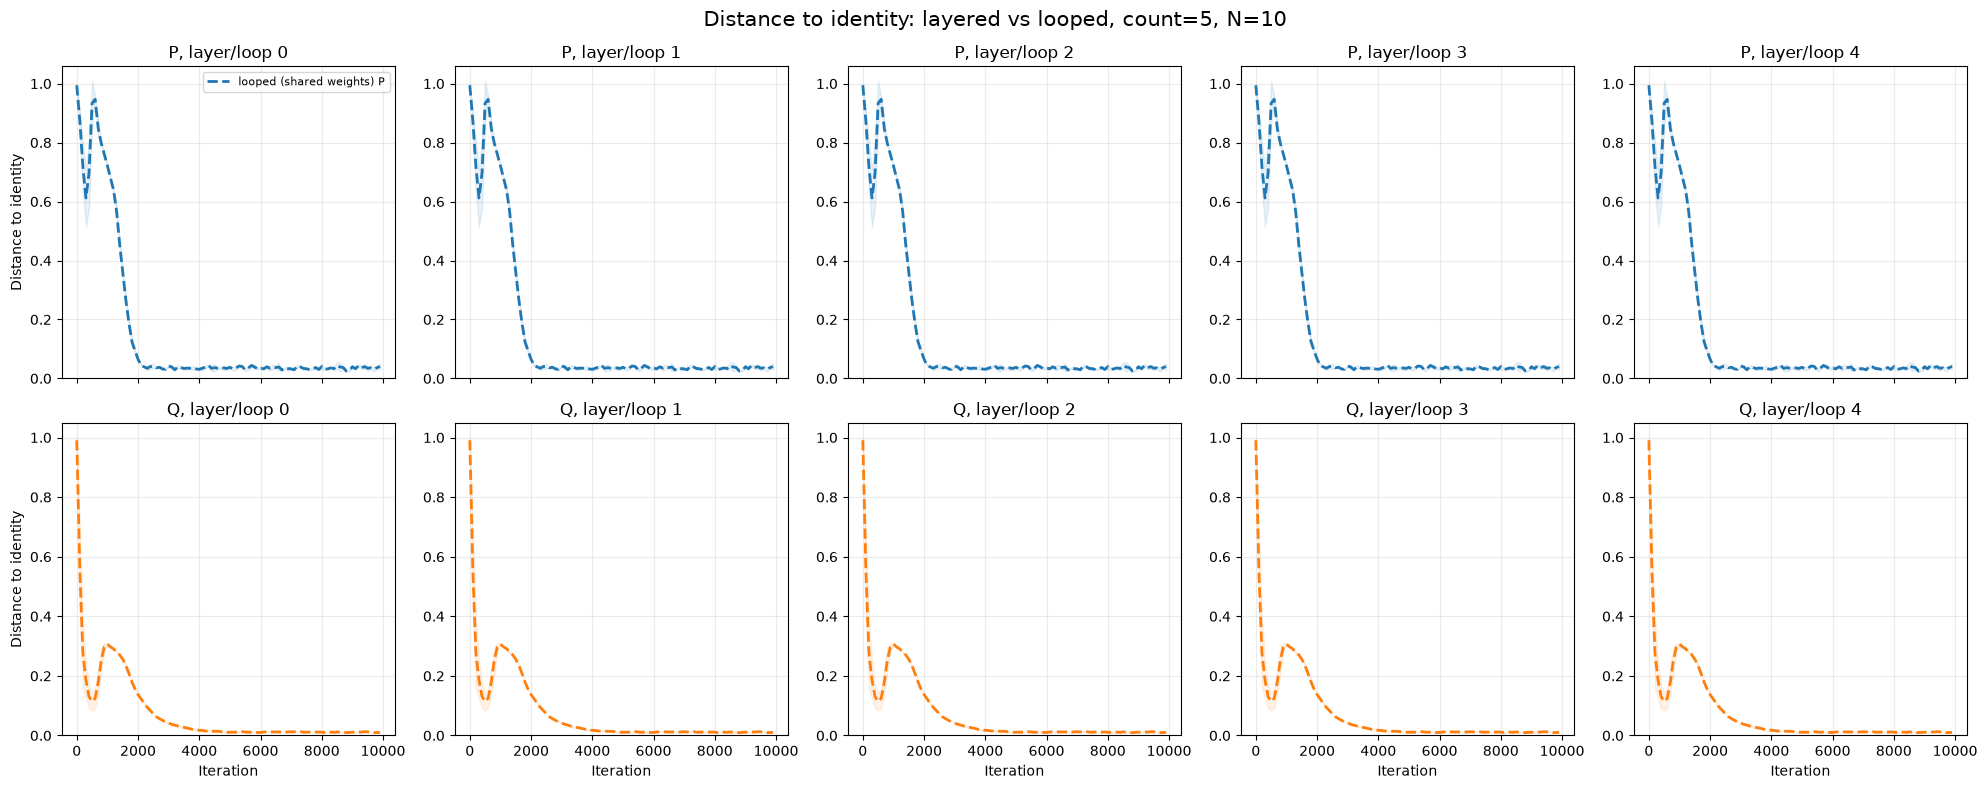

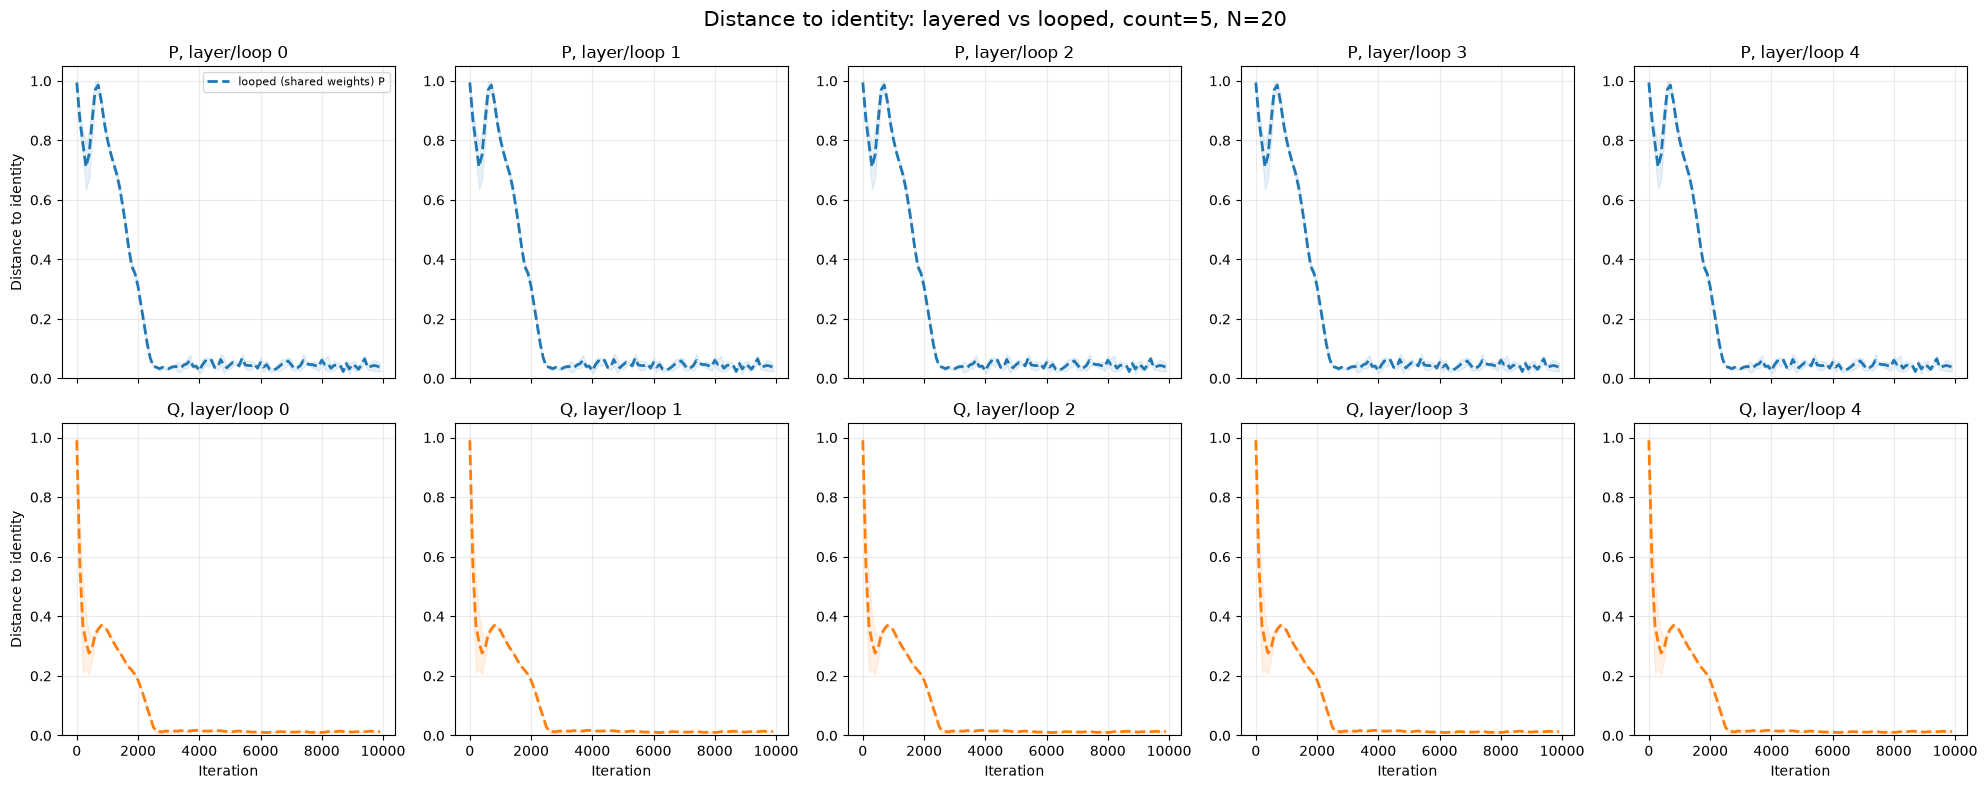

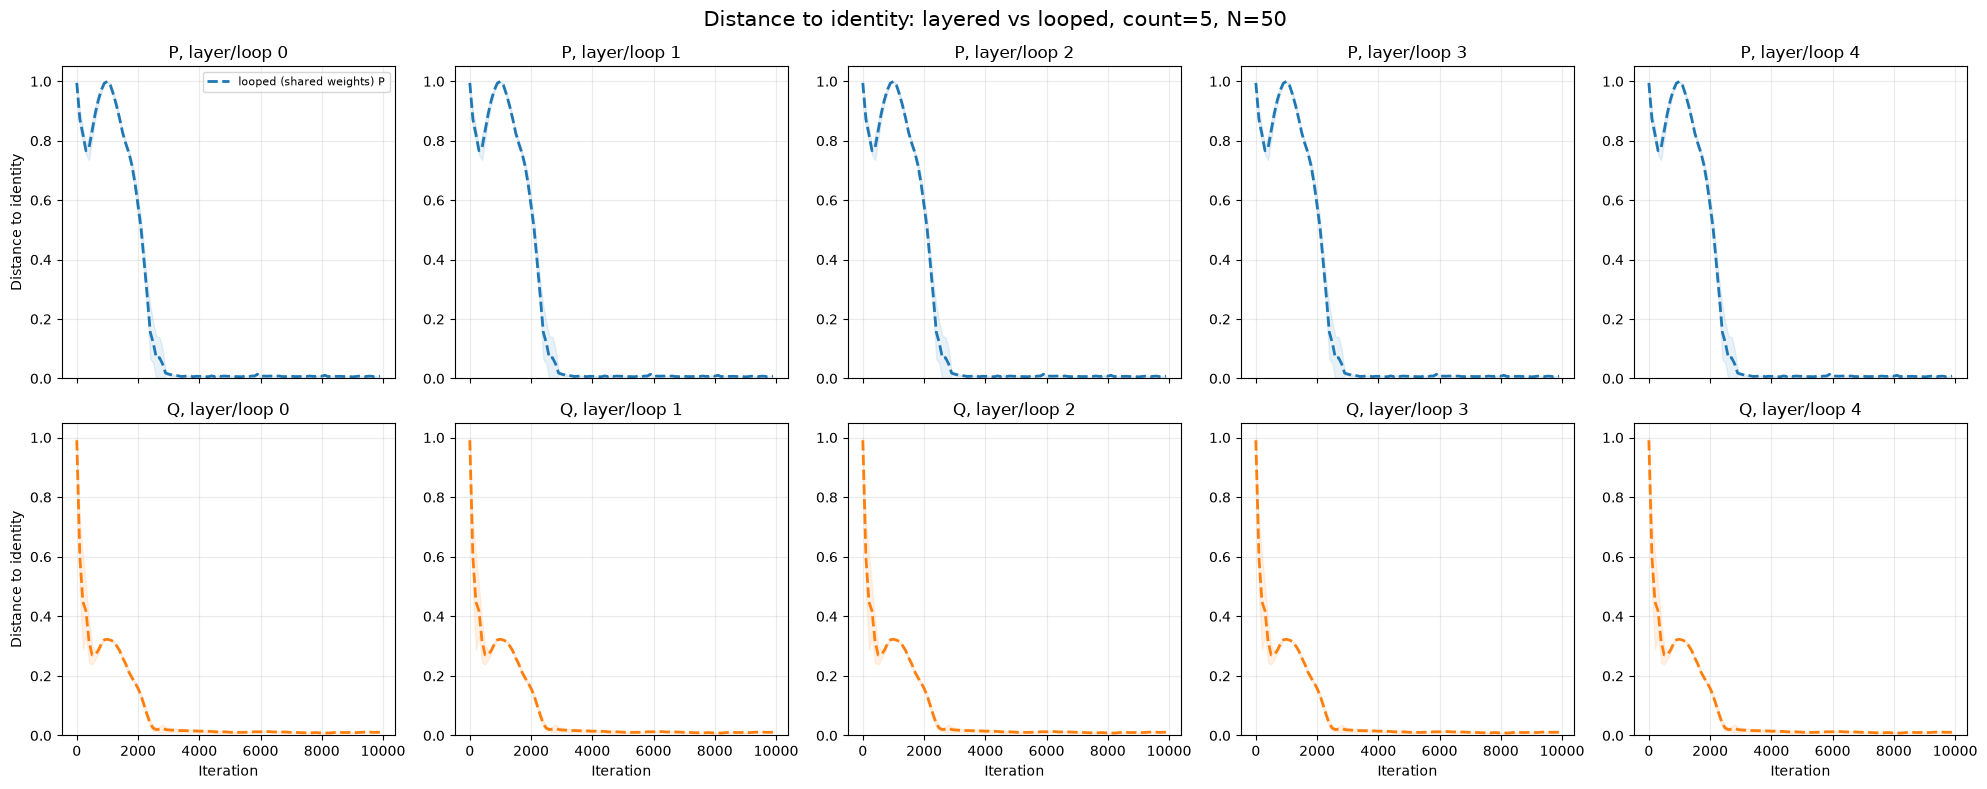

In [25]:
# Figure 1 Experiments
# Looped transformers only, varying the context length N.

f1_seeds = [0, 1, 2]
fig2_N_values = [2, 6, 10, 20, 50]  # N values for figure 2
f1_loop_counts = [5]
f1_model_types = ['looped']
f1_filename = cur_dir + '/figure_one_looped_{}.pth'.format(d)
f1_fig_dir = os.path.join('figures', 'figure_one')
os.makedirs(f1_fig_dir, exist_ok=True)

f1_hist = run_experiment_suite(
    f1_seeds, f1_loop_counts, f1_model_types, f1_filename, context_lengths=fig2_N_values)
f1_loss = compute_loss_dict(f1_hist)
f1_dist = compute_dist_dict(f1_hist, iterations, n_head, hist_stride=hist_stride)

plot_loss_curves(f1_loss, f1_loop_counts, f1_model_types, iterations,
                 fig_dir=f1_fig_dir, filename='figure_one_test_loss.pdf')
plot_parameter_matrices(f1_hist, f1_seeds[0], f1_loop_counts, f1_model_types, n_head,
                        hist_stride=hist_stride, fig_dir=f1_fig_dir)
plot_dist_to_identity(f1_dist, f1_loop_counts, iterations, fig_dir=f1_fig_dir)
